<a href="https://colab.research.google.com/github/faiz-al123/ProyekAkhir_5A_Students_Performancein_Exams/blob/main/03_varian_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Nama:** Nazwa Hummaimah Shiddqin

**NIM:** 2488010039

**Kelas:** Informatika 5A

**Dataset:** Student Performance

**Metode:** Klasifikasi (k-NN dan Naive Bayes)

**Varian:** Varian 2 (Parameter)

Sel-0 Samakan versi scikit-learn

In [ ]:
!pip install -q scikit-learn==1.9.1

In [ ]:
import sklearn
print("scikit-learn :", sklearn.__version__)
assert sklearn.__version__ == "1.9.1", "Versi belum sesuai: jalankan sel pip di atas, lalu Runtime -> Restart session, lalu jalankan ulang dari sel paling atas."
print("Versi sudah sesuai")

scikit-learn : 1.9.1
Versi sudah sesuai


Sel 1 — Import Library

In [ ]:
import io, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, sklearn

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (accuracy_score, f1_score, precision_score,
                             recall_score, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay)

import warnings
warnings.filterwarnings('ignore')

# Konfigurasi bersama (SAMA dengan Anggota 1 dan 3)
RANDOM_STATE = 42
TEST_SIZE = 0.2
K_LIST = [3, 5, 7, 9, 11, 15]   # variasi parameter khusus Varian 2

print("Library berhasil diimport!")

Library berhasil diimport!


Sel-2 Memuat Data

In [ ]:

def baca_data(sumber):
    # Berkas bisa berformat CSV atau Excel meskipun berekstensi .xls
    try:
        return pd.read_csv(sumber)
    except Exception:
        if hasattr(sumber, 'seek'):
            sumber.seek(0)
        return pd.read_excel(sumber)

try:
    from google.colab import files
    uploaded = files.upload()
    file_name = list(uploaded.keys())[0]
    df = baca_data(io.BytesIO(uploaded[file_name]))
except ImportError:
    # Di luar Colab: ganti dengan path berkas Anda
    file_name = 'StudentsPerformance.xls'
    df = baca_data(file_name)

# Buang kolom turunan 'average_score' jika memakai berkas hasil praproses
df = df.drop(columns=['average_score'], errors='ignore')
df.columns = df.columns.str.strip()

print(f"Dataset '{file_name}' berhasil dimuat!")
print("Ukuran dataset (baris, kolom):", df.shape)
display(df.head())

Saving StudentsPerformance.csv to StudentsPerformance (1).csv
Dataset 'StudentsPerformance (1).csv' berhasil dimuat!
Ukuran dataset (baris, kolom): (1000, 8)


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


Sel 3 — Pemeriksaan Singkat Data

In [ ]:
print("Nilai kosong per kolom:")
print(df.isnull().sum())
print("\nJumlah baris duplikat:", df.duplicated().sum())

target_col = 'test preparation course'
dist = df[target_col].value_counts()
print("\nDistribusi target:")
print(dist)
baseline = dist.max() / dist.sum()
print(f"\nAkurasi baseline (selalu menebak kelas mayoritas): {baseline:.3f}")

Nilai kosong per kolom:
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

Jumlah baris duplikat: 0

Distribusi target:
test preparation course
none         642
completed    358
Name: count, dtype: int64

Akurasi baseline (selalu menebak kelas mayoritas): 0.642


Sel 4 — Memisahkan Fitur dan Target

In [ ]:
y = (df[target_col] == 'completed').astype(int)
X = df.drop(columns=[target_col])

num_cols = ['math score', 'reading score', 'writing score']
cat_cols = ['gender', 'race/ethnicity', 'parental level of education', 'lunch']

print("Fitur numerik    :", num_cols)
print("Fitur kategorikal:", cat_cols)
print("Jumlah fitur asli (tujuh fitur):", X.shape[1])

Fitur numerik    : ['math score', 'reading score', 'writing score']
Fitur kategorikal: ['gender', 'race/ethnicity', 'parental level of education', 'lunch']
Jumlah fitur asli (tujuh fitur): 7


Sel 5 — Encoding Fitur Kategorikal (One-Hot)

In [ ]:
X_enc = pd.get_dummies(X, columns=cat_cols, drop_first=True, dtype=int)

print("Jumlah fitur setelah encoding:", X_enc.shape[1])
print("Nama kolom:", list(X_enc.columns))
display(X_enc.head())

Jumlah fitur setelah encoding: 14
Nama kolom: ['math score', 'reading score', 'writing score', 'gender_male', 'race/ethnicity_group B', 'race/ethnicity_group C', 'race/ethnicity_group D', 'race/ethnicity_group E', "parental level of education_bachelor's degree", 'parental level of education_high school', "parental level of education_master's degree", 'parental level of education_some college', 'parental level of education_some high school', 'lunch_standard']


,math score,reading score,writing score,gender_male,race/ethnicity_group B,race/ethnicity_group C,race/ethnicity_group D,race/ethnicity_group E,parental level of education_bachelor's degree,parental level of education_high school,parental level of education_master's degree,parental level of education_some college,parental level of education_some high school,lunch_standard
0,72,72,74,0,1,0,0,0,1,0,0,0,0,1
1,69,90,88,0,0,1,0,0,0,0,0,1,0,1
2,90,95,93,0,1,0,0,0,0,0,1,0,0,1
3,47,57,44,1,0,0,0,0,0,0,0,0,0,0
4,76,78,75,1,0,1,0,0,0,0,0,1,0,1


Sel 6 — Membagi Data Latih dan Data Uji (Stratified)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X_enc, y,
    test_size=TEST_SIZE,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Data latih:", X_train.shape, "| Data uji:", X_test.shape)
print(f"Proporsi 'completed' -> Asli: {y.mean():.3f} | Latih: {y_train.mean():.3f} | Uji: {y_test.mean():.3f}")

Data latih: (800, 14) | Data uji: (200, 14)
Proporsi 'completed' -> Asli: 0.358 | Latih: 0.357 | Uji: 0.360


Sel 7 — Standardisasi Fitur Numerik (Tanpa Kebocoran Data)

In [ ]:
scaler = StandardScaler()

X_train_s = X_train.copy()
X_test_s = X_test.copy()

X_train_s[num_cols] = scaler.fit_transform(X_train[num_cols])   # fit HANYA di data latih
X_test_s[num_cols] = scaler.transform(X_test[num_cols])         # data uji: transform saja

print("Mean data latih setelah standardisasi (harus ~0):")
print(X_train_s[num_cols].mean().round(3))
print("\nStd data latih setelah standardisasi (harus ~1):")
print(X_train_s[num_cols].std().round(3))

Mean data latih setelah standardisasi (harus ~0):
math score      -0.0
reading score    0.0
writing score   -0.0
dtype: float64

Std data latih setelah standardisasi (harus ~1):
math score       1.001
reading score    1.001
writing score    1.001
dtype: float64


Sel 8 — Melatih Model k-NN untuk Setiap Nilai k

In [ ]:
model_k, pred_k, rows = {}, {}, []

for k in K_LIST:
    m = KNeighborsClassifier(n_neighbors=k).fit(X_train_s, y_train)
    p = m.predict(X_test_s)
    model_k[k], pred_k[k] = m, p
    tn_, fp_, fn_, tp_ = confusion_matrix(y_test, p).ravel()
    rows.append({
        'k': k,
        'akurasi_latih': accuracy_score(y_train, m.predict(X_train_s)),
        'akurasi_uji': accuracy_score(y_test, p),
        'precision': precision_score(y_test, p, zero_division=0),
        'recall': recall_score(y_test, p, zero_division=0),
        'f1_completed': f1_score(y_test, p, zero_division=0),
        'f1_macro': f1_score(y_test, p, average='macro', zero_division=0),
        'TN': tn_, 'FP': fp_, 'FN': fn_, 'TP': tp_,
    })

df_k = pd.DataFrame(rows)
display(df_k.round(4))
print(f"Baseline akurasi: {baseline:.4f}")

,k,akurasi_latih,akurasi_uji,precision,recall,f1_completed,f1_macro,TN,FP,FN,TP
0,3,0.8125,0.560,0.3750,0.3333,0.3529,0.5098,88,40,48,24
1,5,0.7388,0.575,0.3818,0.2917,0.3307,0.5097,94,34,51,21
2,7,0.7238,0.630,0.4800,0.3333,0.3934,0.5636,102,26,48,24
3,9,0.7000,0.600,0.4167,0.2778,0.3333,0.5238,100,28,52,20
4,11,0.6975,0.585,0.3778,0.2361,0.2906,0.4987,100,28,55,17
5,15,0.6862,0.680,0.5952,0.3472,0.4386,0.6074,111,17,47,25


Baseline akurasi: 0.6420


## Sel 9 — Validasi Silang (CV) pada Data Latih

In [ ]:
from sklearn.model_selection import GridSearchCV

# Menggunakan RANDOM_STATE yang telah didefinisikan sebelumnya
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

alur_knn = Pipeline([
    ('prep', ColumnTransformer([('num', StandardScaler(), num_cols)],
                               remainder='passthrough')),
    ('model', KNeighborsClassifier()),
])
ruang_knn = {'model__n_neighbors': K_LIST}

cari_knn = GridSearchCV(
    alur_knn, ruang_knn, cv=cv, n_jobs=-1,
    scoring={'f1_macro': 'f1_macro', 'accuracy': 'accuracy', 'f1': 'f1'},
    refit='f1_macro',
)
cari_knn.fit(X_train, y_train)      # data latih TANPA scaling manual; scaler ada di Pipeline

hs = cari_knn.cv_results_
df_cv = pd.DataFrame({
    'k': hs['param_model__n_neighbors'].data.astype(int),
    'cv_f1_macro': hs['mean_test_f1_macro'],
    'cv_f1_macro_std': hs['std_test_f1_macro'],
    'cv_akurasi': hs['mean_test_accuracy'],
    'cv_akurasi_std': hs['std_test_accuracy'],
    'cv_f1_completed': hs['mean_test_f1'],
})
df_all = df_k.merge(df_cv, on='k')

print('Parameter terbaik :', cari_knn.best_params_)
print('Skor f1_macro CV  :', round(cari_knn.best_score_, 4))
display(df_cv.round(4))

Parameter terbaik : {'model__n_neighbors': 3}
Skor f1_macro CV  : 0.5572


,k,cv_f1_macro,cv_f1_macro_std,cv_akurasi,cv_akurasi_std,cv_f1_completed
0,3,0.5572,0.0219,0.6250,0.0190,0.3843
1,5,0.5394,0.0243,0.6088,0.0297,0.3619
2,7,0.5476,0.0212,0.6238,0.0294,0.3631
3,9,0.5412,0.0317,0.6262,0.0322,0.3438
4,11,0.5300,0.0246,0.6238,0.0266,0.3206
5,15,0.5491,0.0462,0.6425,0.0410,0.3443


## Sel 10 — Menentukan k Terbaik

In [ ]:
best_k = int(cari_knn.best_params_['model__n_neighbors'])
best_k_acc_cv = int(df_all.sort_values('cv_akurasi', ascending=False).iloc[0]['k'])
best_k_uji = int(df_all.sort_values('akurasi_uji', ascending=False).iloc[0]['k'])

print(f"k terbaik berdasarkan f1_macro CV (utama): {best_k}")
print(f"k dengan akurasi CV tertinggi            : {best_k_acc_cv}")
print(f"k dengan akurasi uji tertinggi           : {best_k_uji}")
if len({best_k, best_k_acc_cv, best_k_uji}) > 1:
    print("-> Kriteria memberi k berbeda. Dasar pemilihan resmi: f1_macro CV. Bahas selisihnya di interpretasi.")

baris = df_all[df_all['k'] == best_k].iloc[0]
acc, f1, f1_macro = baris['akurasi_uji'], baris['f1_completed'], baris['f1_macro']
print(f"\nHasil data uji untuk k={best_k}: akurasi={acc:.4f}, F1(completed)={f1:.4f}, F1 macro={f1_macro:.4f}")
print(f"Selisih akurasi terhadap baseline: {acc - baseline:+.4f}")

print(f"\nClassification report (k={best_k}):")
print(classification_report(y_test, pred_k[best_k],
                            target_names=['none', 'completed'], zero_division=0))

k terbaik berdasarkan f1_macro CV (utama): 3
k dengan akurasi CV tertinggi            : 15
k dengan akurasi uji tertinggi           : 15
-> Kriteria memberi k berbeda. Dasar pemilihan resmi: f1_macro CV. Bahas selisihnya di interpretasi.

Hasil data uji untuk k=3: akurasi=0.5600, F1(completed)=0.3529, F1 macro=0.5098
Selisih akurasi terhadap baseline: -0.0820

Classification report (k=3):
              precision    recall  f1-score   support

        none       0.65      0.69      0.67       128
   completed       0.38      0.33      0.35        72

    accuracy                           0.56       200
   macro avg       0.51      0.51      0.51       200
weighted avg       0.55      0.56      0.55       200



## Sel 11 — Grafik Akurasi dan F1 terhadap k

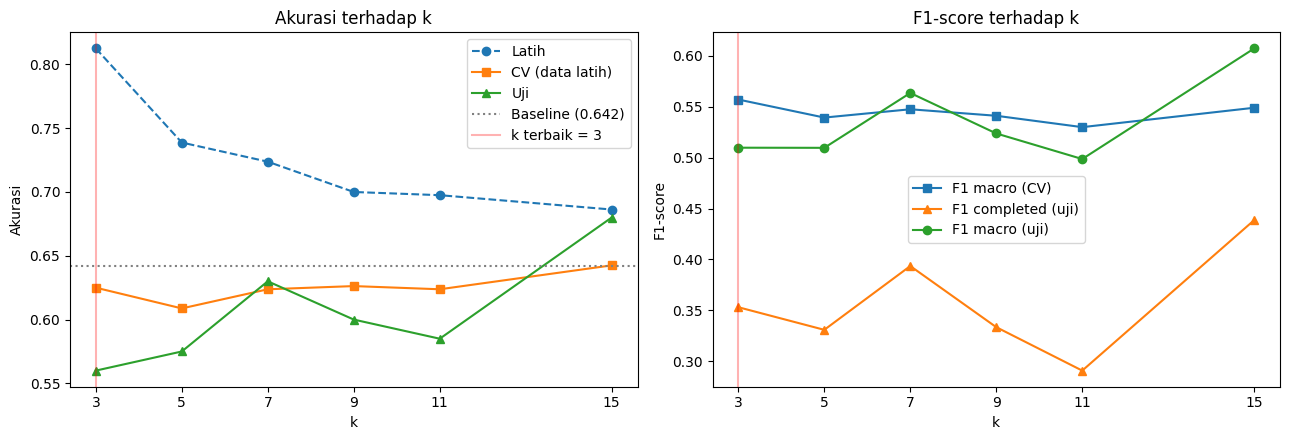

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

ax = axes[0]
ax.plot(df_all['k'], df_all['akurasi_latih'], 'o--', label='Latih')
ax.plot(df_all['k'], df_all['cv_akurasi'], 's-', label='CV (data latih)')
ax.plot(df_all['k'], df_all['akurasi_uji'], '^-', label='Uji')
ax.axhline(baseline, color='gray', linestyle=':', label=f'Baseline ({baseline:.3f})')
ax.axvline(best_k, color='red', alpha=0.3, label=f'k terbaik = {best_k}')
ax.set_xticks(K_LIST); ax.set_xlabel('k'); ax.set_ylabel('Akurasi')
ax.set_title('Akurasi terhadap k'); ax.legend()

ax = axes[1]
ax.plot(df_all['k'], df_all['cv_f1_macro'], 's-', label='F1 macro (CV)')
ax.plot(df_all['k'], df_all['f1_completed'], '^-', label='F1 completed (uji)')
ax.plot(df_all['k'], df_all['f1_macro'], 'o-', label='F1 macro (uji)')
ax.axvline(best_k, color='red', alpha=0.3)
ax.set_xticks(K_LIST); ax.set_xlabel('k'); ax.set_ylabel('F1-score')
ax.set_title('F1-score terhadap k'); ax.legend()

plt.tight_layout(); plt.show()

## Sel 12 — Confusion Matrix

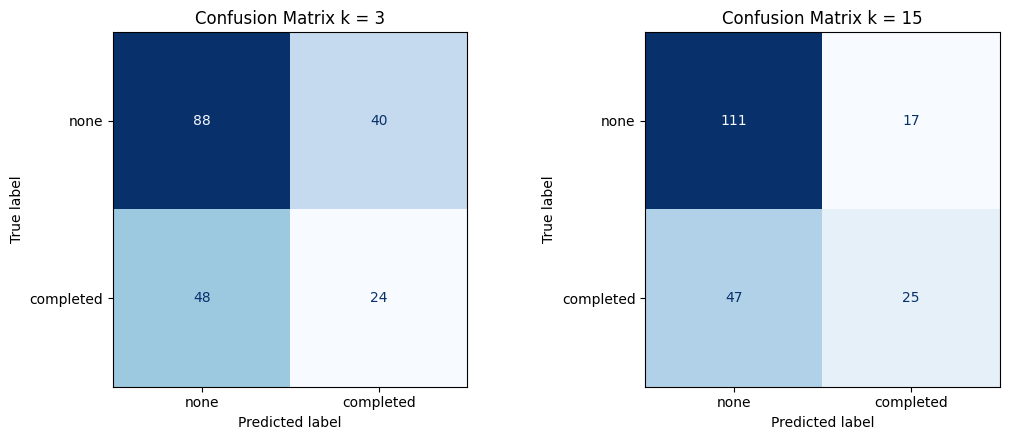

k = 3: TN = 88 | FP = 40 | FN = 48 | TP = 24
Dari 72 siswa 'completed', 24 terdeteksi benar (recall 33.33%).
Dari 128 siswa 'none', 88 terdeteksi benar (specificity 68.75%).


In [ ]:
k_banding = max(K_LIST)
pasangan = [best_k] if best_k == k_banding else [best_k, k_banding]

fig, axes = plt.subplots(1, len(pasangan), figsize=(5.5 * len(pasangan), 4.5))
axes = np.atleast_1d(axes)
for ax, k in zip(axes, pasangan):
    cm_k = confusion_matrix(y_test, pred_k[k])
    ConfusionMatrixDisplay(cm_k, display_labels=['none', 'completed']).plot(
        ax=ax, cmap='Blues', colorbar=False, values_format='d')
    ax.set_title(f'Confusion Matrix k = {k}')
plt.tight_layout(); plt.show()

cm = confusion_matrix(y_test, pred_k[best_k])
tn, fp, fn, tp = cm.ravel()
print(f"k = {best_k}: TN = {tn} | FP = {fp} | FN = {fn} | TP = {tp}")
print(f"Dari {tp + fn} siswa 'completed', {tp} terdeteksi benar (recall {tp/(tp+fn):.2%}).")
print(f"Dari {tn + fp} siswa 'none', {tn} terdeteksi benar (specificity {tn/(tn+fp):.2%}).")

## Sel 13 — Perbandingan dengan Baseline dan Varian 2

,Model,Akurasi,F1 (completed),F1 macro
0,Baseline (selalu none),0.640,0.0000,0.3902
1,k-NN (k=3) <- terbaik (CV),0.560,0.3529,0.5098
2,k-NN (k=5),0.575,0.3307,0.5097
3,k-NN (k=7),0.630,0.3934,0.5636
4,k-NN (k=9),0.600,0.3333,0.5238
5,k-NN (k=11),0.585,0.2906,0.4987
6,k-NN (k=15),0.680,0.4386,0.6074


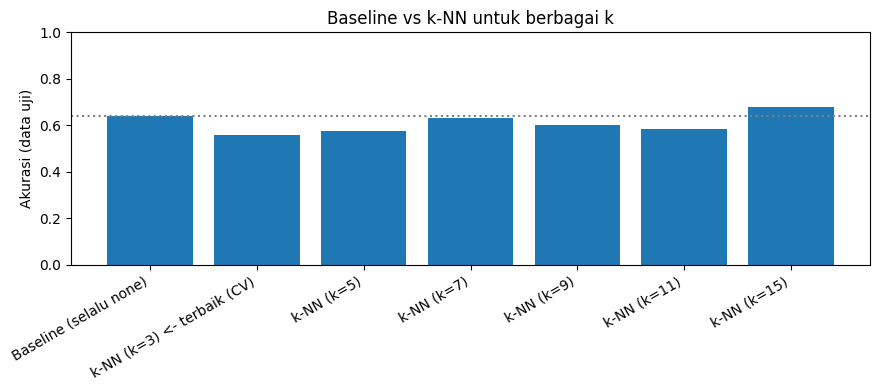

In [ ]:
y_base = np.zeros_like(y_test)
banding = pd.DataFrame([
    {'Model': 'Baseline (selalu none)',
     'Akurasi': accuracy_score(y_test, y_base),
     'F1 (completed)': f1_score(y_test, y_base, zero_division=0),
     'F1 macro': f1_score(y_test, y_base, average='macro', zero_division=0)},
] + [
    {'Model': f'k-NN (k={r.k})' + (' <- terbaik (CV)' if r.k == best_k else ''),
     'Akurasi': r.akurasi_uji, 'F1 (completed)': r.f1_completed, 'F1 macro': r.f1_macro}
    for r in df_all.itertuples()
])
display(banding.round(4))

plt.figure(figsize=(9, 4))
plt.bar(banding['Model'], banding['Akurasi'])
plt.axhline(baseline, color='gray', linestyle=':')
plt.xticks(rotation=30, ha='right'); plt.ylim(0, 1)
plt.ylabel('Akurasi (data uji)'); plt.title('Baseline vs k-NN untuk berbagai k')
plt.tight_layout(); plt.show()

## Sel 14 — Ringkasan Hasil Varian 2 (untuk Tabel Perbandingan Kelompok)

In [ ]:
hasil_varian2 = pd.DataFrame([{
    'Varian': '2 - Parameter',
    'Model': f'k-NN (k={best_k})',
    'Fitur': f'{X_enc.shape[1]} kolom (7 fitur asli, setelah one-hot)',
    'Akurasi': round(float(acc), 4),
    'F1 (completed)': round(float(f1), 4),
    'F1 macro': round(float(f1_macro), 4),
    'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp),
}])
display(hasil_varian2)
hasil_varian2.to_csv('hasil_varian_2.csv', index=False)

# Tabel lengkap semua k (untuk laporan)
df_all.round(4).to_csv('hasil_varian_2_semua_k.csv', index=False)
print("Disimpan: hasil_varian_2.csv dan hasil_varian_2_semua_k.csv")

,Varian,Model,Fitur,Akurasi,F1 (completed),F1 macro,TN,FP,FN,TP
0,2 - Parameter,k-NN (k=3),"14 kolom (7 fitur asli, setelah one-hot)",0.56,0.3529,0.5098,88,40,48,24


Disimpan: hasil_varian_2.csv dan hasil_varian_2_semua_k.csv


Sel 14 — Menyimpan Artefak untuk Pertemuan 13

In [ ]:
import os, joblib, sklearn
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.neighbors import KNeighborsClassifier

# False = simpan di Colab lalu unduh ke komputer (tanpa Google Drive)
# True  = simpan ke Google Drive
USE_DRIVE = False

if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    FOLDER = '/content/drive/MyDrive/proyek_akhir_ml'
else:
    FOLDER = 'proyek_akhir_ml'
os.makedirs(FOLDER, exist_ok=True)

# Data mentah dengan baris yang sama persis seperti pembagian di Sel 6
X_train_raw = X.loc[X_train.index]
X_test_raw = X.loc[X_test.index]

# Pipeline lengkap (praproses + model) dengan k terbaik, dilatih pada data mentah
knn_terbaik = Pipeline([
    ('prep', ColumnTransformer([
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_cols),
    ])),
    ('model', KNeighborsClassifier(n_neighbors=best_k)),
])
knn_terbaik.fit(X_train_raw, y_train)

# Pemeriksaan: harus True
y_pred = pred_k[best_k]
print("Prediksi pipeline = prediksi Sel 8:",
      bool((knn_terbaik.predict(X_test_raw) == y_pred).all()))

kolom_enc = int(knn_terbaik.named_steps['prep'].transform(X_test_raw).shape[1])
print("Kolom setelah encoding:", kolom_enc)

artefak = {
    'X_train': X_train_raw, 'X_test': X_test_raw,
    'y_train': y_train, 'y_test': y_test,
    'numerik': num_cols, 'kategorik': cat_cols,
    'knn': knn_terbaik, 'nb': None,                 # Naive Bayes dikerjakan Varian 3
    'param_knn': cari_knn.best_params_, 'param_nb': None,
    'cv_knn': float(cari_knn.best_score_), 'cv_nb': None,   # f1_macro CV
    'kolom_encoding': kolom_enc,
    'seed': RANDOM_STATE, 'versi_sklearn': sklearn.__version__,
    # tambahan khusus Varian 2
    'metrik_cv': 'f1_macro', 'k': best_k, 'test_size': TEST_SIZE,
    'hasil_uji': {'akurasi': float(acc), 'f1_completed': float(f1),
                  'f1_macro': float(f1_macro), 'baseline': float(baseline),
                  'confusion_matrix': cm.tolist()},
    'hasil_semua_k': df_all.round(4).to_dict(orient='records'),
}

jalur = os.path.join(FOLDER, 'artefak_p12.joblib')
joblib.dump(artefak, jalur)
print('Tersimpan:', jalur)
print('Ukuran   :', round(os.path.getsize(jalur) / 1024, 1), 'KB')

# Tanpa Drive: unduh berkas ke komputer (penyimpanan sementara Colab hilang saat runtime mati)
if not USE_DRIVE:
    try:
        from google.colab import files
        files.download(jalur)
    except ImportError:
        pass

Prediksi pipeline = prediksi Sel 8: True
Kolom setelah encoding: 14
Tersimpan: proyek_akhir_ml/artefak_p12.joblib
Ukuran   : 274.8 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Sel-15 Uji Muat Ulang Artefak

In [ ]:
muat = joblib.load(jalur)
print("Kunci artefak:", list(muat.keys()))
print("Versi sklearn saat disimpan:", muat['versi_sklearn'], "| sekarang:", sklearn.__version__)

pred_muat = muat['knn'].predict(muat['X_test'])
print("Prediksi identik dengan model asli:", bool((pred_muat == y_pred).all()))

Kunci artefak: ['X_train', 'X_test', 'y_train', 'y_test', 'numerik', 'kategorik', 'knn', 'nb', 'param_knn', 'param_nb', 'cv_knn', 'cv_nb', 'kolom_encoding', 'seed', 'versi_sklearn', 'metrik_cv', 'k', 'test_size', 'hasil_uji', 'hasil_semua_k']
Versi sklearn saat disimpan: 1.9.1 | sekarang: 1.9.1
Prediksi identik dengan model asli: True


## Sel 16 — Interpretasi Hasil

**1. Bagaimana pengaruh k terhadap akurasi dan F1?**

Tidak ada tren yang rapi: nilai naik-turun saat k membesar. Akurasi uji berturut-turut untuk k = 3, 5, 7, 9, 11, 15 adalah 0,560; 0,575; 0,630; 0,600; 0,585; 0,680. F1 kelas `completed` juga tidak beraturan (0,353; 0,331; 0,393; 0,333; 0,291; 0,439). Pada validasi silang, F1 macro nyaris datar di kisaran 0,530–0,557 dan akurasi CV hanya bergerak dari 0,609 ke 0,643. Kriteria yang berbeda memberi k terbaik yang berbeda. Berdasarkan F1 macro CV, k terbaik adalah **k = 3** (0,5572). Berdasarkan akurasi CV (0,6425) dan akurasi uji (0,680), k terbaik adalah **k = 15**.

**2. Apakah ada tanda overfitting pada k kecil?**

Ada. Pada k = 3 akurasi latih 0,8125, tetapi akurasi CV hanya 0,625 dan akurasi uji 0,560, jadi jaraknya sekitar 19 poin (latih–CV) dan 25 poin (latih–uji). Pada k = 15 akurasi latih turun menjadi 0,6862, dekat dengan akurasi CV 0,6425 (selisih sekitar 4 poin). Akurasi latih turun terus dari 0,8125 ke 0,6862 seiring k membesar, artinya model makin "halus" dan makin sedikit menghafal data latih. Namun k = 3 yang menghafal lebih banyak tidak menghasilkan akurasi uji yang lebih baik.

**3. Apa yang terjadi pada confusion matrix saat k membesar?**

Prediksi memang makin condong ke `none`. Pada k = 3 model memprediksi 136 siswa sebagai `none` (TN 88 + FN 48) dan 64 sebagai `completed`. Pada k = 15 jumlahnya menjadi 158 `none` (TN 111 + FN 47) dan 42 `completed`. Kenaikan akurasi di k = 15 terutama berasal dari berkurangnya FP (40 menjadi 17), bukan dari FN yang membaik (48 menjadi 47) atau TP yang melonjak (24 menjadi 25). Hasil di antaranya tidak monoton. FN `completed` naik sampai 55 pada k = 11 dan recall turun ke 23,6%, lalu recall kembali ke 34,7% pada k = 15. Jadi recall `completed` rendah di semua k (23,6%–34,7%), dan model selalu lebih mudah mengenali `none` (specificity 68,75% pada k = 3 dan 86,7% pada k = 15).

**4. Apakah model lebih baik daripada baseline?**

Belum meyakinkan. Baseline (selalu menebak `none`) memberi akurasi 0,642 (0,640 pada data uji). Pada k terbaik resmi (k = 3), akurasi uji 0,560, yaitu 8,2 poin di bawah baseline. Akurasi tertinggi di k = 15 (0,680) hanya 4 poin di atas baseline, setara sekitar 8 siswa dari 200. Akurasi CV k = 15 (0,6425) pun praktis sama dengan baseline. Kenaikan akurasi ke arah baseline ini sebagian besar karena model makin sering menebak `none` (kelas mayoritas), bukan karena makin mampu membedakan kelas. Satu-satunya keunggulan jelas ada pada F1: baseline punya F1 `completed` = 0 dan F1 macro 0,3902, sedangkan k-NN mencapai F1 `completed` 0,29–0,44 dan F1 macro 0,50–0,61. Jadi model sedikit lebih baik dalam mengenali kelas minoritas, tetapi masih lemah (F1 `completed` terbaik hanya 0,4386).

**5. Apakah selisih antar k bermakna?**

Kebanyakan tidak. Simpangan baku CV berkisar 0,019–0,041 untuk akurasi dan 0,021–0,046 untuk F1 macro, sama besar atau lebih besar daripada selisih antar k (F1 macro CV hanya berjarak 0,0272 antara nilai tertinggi dan terendah). Data uji hanya 200 siswa dengan 72 di kelas `completed`, jadi satu siswa saja setara 0,5 poin akurasi. Galat baku akurasi uji sekitar 3,5 poin, sehingga selisih 1–2 poin (misalnya k = 3 vs k = 5: 0,560 vs 0,575) hanyalah beberapa siswa dan bisa murni kebetulan. Loncatan k = 15 (0,680) juga tidak dikuatkan oleh CV, yang selisihnya dengan k lain hanya 1,6–3,4 poin dan simpangan bakunya sendiri paling besar (0,041).

**6. Jika k-NN dibandingkan dengan Varian 1 (k=5), apa penyebab hasilnya berbeda atau tidak banyak berubah?**

 k = 5 memberi akurasi 0,575, F1 `completed` 0,3307, dan F1 macro 0,5097. Nilai F1 macro ini hampir sama dengan k = 3 (0,5098), sehingga hasil pada Varian 2 tidak banyak berubah dari Varian 1 meskipun k diubah-ubah. Penyebab yang paling masuk akal adalah fitur yang lemah: seperti terlihat pada eksplorasi, selisih rata-rata nilai antar kelas `completed` dan `none` kecil dan distribusinya saling tumpang tindih, sehingga tetangga terdekat sering berasal dari kelas yang berbeda. Dari 14 kolom hasil one-hot, 11 kolom adalah biner kategorikal yang kurang informatif, dan semuanya ikut menghitung jarak. Mengubah k hanya mengubah seberapa halus batas keputusan, tidak menambah informasi pembeda yang tidak ada di data.

**7. Kesimpulan Varian 2**

Berdasarkan kriteria resmi F1 macro CV, k terbaik adalah **k = 3** (CV F1 macro 0,5572), dengan kinerja uji akurasi 0,560, F1 `completed` 0,3529, dan F1 macro 0,5098 (TN 88, FP 40, FN 48, TP 24). Namun pilihan ini lemah: akurasinya 8,2 poin di bawah baseline, ada tanda overfitting (akurasi latih 0,8125 vs CV 0,625), dan selisihnya dengan k lain masih berada dalam simpangan baku CV. Sebagai pembanding, k = 15 unggul pada akurasi CV (0,6425) dan akurasi uji (0,680) dengan F1 `completed` 0,4386, tetapi keunggulan itu sebagian karena prediksi condong ke `none` dan hanya selisih beberapa siswa dari baseline. Keterbatasan utama adalah fitur yang lemah, data uji kecil (200), dan recall `completed` yang rendah (23,6%–34,7%) di semua k, sehingga k-NN pada data ini belum bisa diandalkan untuk mendeteksi siswa yang mengikuti kursus persiapan. k = 3 diserahkan ke Anggota 3 sebagai k terbaik untuk dibandingkan dengan Naive Bayes, dengan catatan k = 15 sebagai alternatif.